运行约定：以本 Notebook 所在目录作为工作目录，从第一单元顺序运行。首个代码单元仅建立数据与输出目录。历史输出保留，不代表当前环境已验证。


In [ ]:
from pathlib import Path
Path('../data').mkdir(parents=True, exist_ok=True)
Path('../outputs').mkdir(parents=True, exist_ok=True)


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets,transforms,models
import time
from matplotlib import pyplot as plt

# import os
# os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import warnings
warnings.filterwarnings("ignore")

# 一、使用ResNet网络结构创建CIFAR-10分类器

CIFAR-10 是由 Hinton 的学生 Alex Krizhevsky 和 Ilya Sutskever 整理的一个用于识别普适物体的小型数据集。一共包含 10 个类别的 RGB 彩色图 片：飞机（ airlane ）、汽车（ automobile ）、鸟类（ bird ）、猫（ cat ）、鹿（ deer ）、狗（ dog ）、蛙类（ frog ）、马（ horse ）、船（ ship ）和卡车（ truck ）。图片的尺寸为 32×32 ，数据集中一共有 50000 张训练圄片和 10000 张测试图片。 CIFAR-10 的图片样例如图所示。

![](../assets/resnet-1.png)

## 1 下载并加载数据，并做出一定的预先处理

In [ ]:
# 在线下载慢，可以选择直接拷贝

# !cp -r /workspace/DataSet/cvdata/CIFAR10/ ../data/

In [ ]:
pipline_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))  # ImageNet均值方差
])

pipline_test = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])
#下载数据集
train_set = datasets.CIFAR10(root="../data/CIFAR10", train=True, download=True, transform=pipline_train)
test_set = datasets.CIFAR10(root="../data/CIFAR10", train=False, download=True, transform=pipline_test)
#加载数据集
trainloader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(test_set, batch_size=32, shuffle=False)
# 类别信息也是需要我们给定的
classes = ('plane', 'car', 'bird', 'cat','deer', 'dog', 'frog', 'horse', 'ship', 'truck')

## 2&3. 调用torchvision的预训练模型ResNet

In [ ]:
#创建模型，部署gpu
# device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

from torchvision import models
model = models.resnet18(pretrained=True)  # 加载预训练ResNet18
model.fc = nn.Linear(model.fc.in_features, 10)  # 替换最后fc层输出为10类
model = model.to(device)

#定义优化器
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
#optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# # 多卡
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model = models.resnet18(pretrained=True)
# model.fc = nn.Linear(model.fc.in_features, 10)

# if torch.cuda.device_count() > 1:
#     print(f"Let's use {torch.cuda.device_count()} GPUs!")
#     model = nn.DataParallel(model)  # 自动使用所有可用GPU

# model = model.to(device)

# #定义优化器
# optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
# #optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# # 多卡
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model = models.resnet18(pretrained=True)
# model.fc = nn.Linear(model.fc.in_features, 10)

# # 指定使用的GPU设备ID列表，比如用GPU 0和2
# gpu_ids = [2, 3]

# if torch.cuda.is_available() and len(gpu_ids) > 1:
#     print(f"Using GPUs: {gpu_ids}")
#     model = nn.DataParallel(model, device_ids=gpu_ids)

# model = model.to(device)


## 4 定义训练过程

In [ ]:
def train_runner(model, device, trainloader, optimizer, epoch):
    #训练模型, 启用 BatchNormalization 和 Dropout, 将BatchNormalization和Dropout置为True
    model.train()
    total = 0
    correct =0.0
    
    #enumerate迭代已加载的数据集,同时获取数据和数据下标
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        #把模型部署到device上
        inputs, labels = inputs.to(device), labels.to(device)
        #初始化梯度
        optimizer.zero_grad()
        #保存训练结果
        outputs = model(inputs)
        #计算损失和
        #多分类情况通常使用cross_entropy(交叉熵损失函数), 而对于二分类问题, 通常使用sigmod
        loss = F.cross_entropy(outputs, labels)
        #获取最大概率的预测结果
        #dim=1表示返回每一行的最大值对应的列下标
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()
        if i % 1000 == 0:
            #loss.item()表示当前loss的数值
            print("Train Epoch{} \t Loss: {:.6f}, accuracy: {:.6f}%".format(epoch, loss.item(), 100*(correct/total)))
            Loss.append(loss.item())
            Accuracy.append(correct/total)
    return loss.item(), correct/total

## 5 定义测试过程

In [ ]:
def test_runner(model, device, testloader):
    #模型验证, 必须要写, 否则只要有输入数据, 即使不训练, 它也会改变权值
    #因为调用eval()将不启用 BatchNormalization 和 Dropout, BatchNormalization和Dropout置为False
    model.eval()
    #统计模型正确率, 设置初始值
    correct = 0.0
    test_loss = 0.0
    total = 0
    #torch.no_grad将不会计算梯度, 也不会进行反向传播
    with torch.no_grad():
        for data, label in testloader:
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label).item()
            predict = output.argmax(dim=1)
            #计算正确数量
            total += label.size(0)
            correct += (predict == label).sum().item()
        #计算损失值
        print("test_avarage_loss: {:.6f}, accuracy: {:.6f}%".format(test_loss/total, 100*(correct/total)))

## 6 运行

In [ ]:
#调用
epoch = 3
Loss = []
Accuracy = []
for epoch in range(1, epoch+1):
    print("start_time",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())))
    loss, acc = train_runner(model, device, trainloader, optimizer, epoch)
    Loss.append(loss)
    Accuracy.append(acc)
    test_runner(model, device, testloader)
    print("end_time: ",time.strftime('%Y-%m-%d %H:%M:%S',time.localtime(time.time())),'\n')

print('Finished Training')
plt.subplot(2,1,1)
plt.plot(Loss)
plt.title('Loss')
plt.show()
plt.subplot(2,1,2)
plt.plot(Accuracy)
plt.title('Accuracy')
plt.show()

## 7 保存模型

In [ ]:
# !mkdir models

In [ ]:
# print(model)
torch.save(model, '../outputs/model-resnet-cifar10.pth') #保存模型

# torch.save(model.state_dict(), '../outputs/model-cifar10.pth')
# model.load_state_dict(torch.load('../outputs/model-cifar10.pth'))

## 8 模型测试

利用刚刚训练的模型进行CIFAR10类型图片的测试。

In [ ]:
from PIL import Image
import numpy as np

if __name__ == '__main__':
    # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    model = torch.load('../outputs/model-resnet-cifar10.pth', weights_only=False) #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    # 读取要预测的图片
    img = Image.open("../assets/resnet-2.png").convert('RGB') # 读取图像
    #img.show()
    plt.imshow(img) # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，224，224]
    trans = transforms.Compose(
        [
            transforms.Resize((224,224)),
            transforms.ToTensor(),
            transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
        ])
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    # print(predict.item())
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    pred_class = classes[predicted.item()]
    print("预测类别：",pred_class)

## 9 炫酷版本


▶ Loading CIFAR-10 Dataset
[INFO] Training samples: 50000
[INFO] Testing samples: 10000
[INFO] Classes: ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

             ResNet-18 CIFAR-10 Training System             

System Information:
  ▸ Date:        2026-01-10 00:58:57
  ▸ Platform:    darwin
  ▸ PyTorch:     2.8.0
  ▸ Device:      Apple Silicon GPU (MPS)
  ▸ MPS Status:   Available ✅
  ▸ MPS Built:    True ✅

Training Configuration:
  ▸ Model:       ResNet-18 (pretrained)
  ▸ Optimizer:   SGD with momentum
  ▸ LR:          0.01
  ▸ Momentum:    0.9
  ▸ Batch Size:  Train: 64, Test: 32
  ▸ Epochs:       3
  ▸ Classes:     10 classes
  ▸ Save Dir:    ./models/

──────────────────────────────────────────────────

▶ Creating ResNet-18 Model
[INFO] Using pretrained weights: True
[INFO] Model adapted for 10 classes

▶ Model Architecture
ResNet-18 Architecture Summary:

Total params: 11,181,642
Trainable params: 11,181,642
Non-trainable params: 0

Key Laye

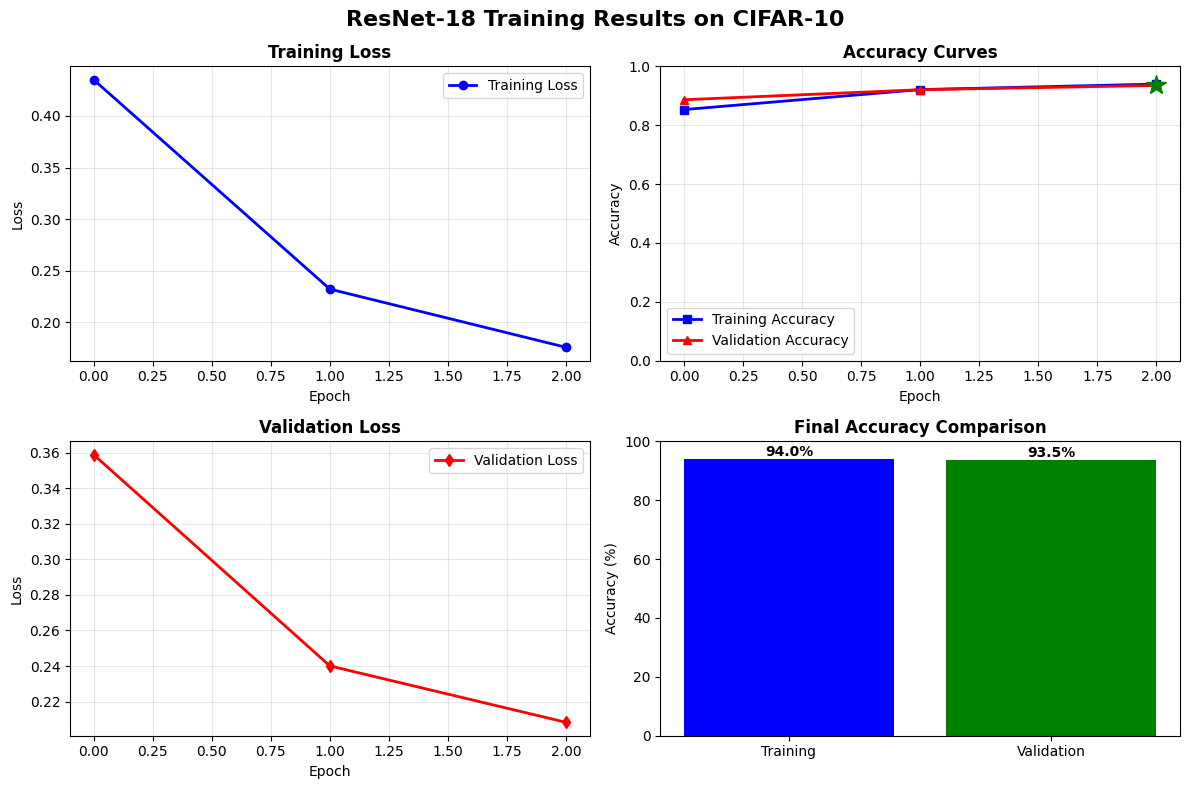

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
import sys
import os
import numpy as np
from datetime import datetime
from torchvision import datasets, transforms, models
import shutil
import warnings
warnings.filterwarnings("ignore")

# 添加颜色和样式定义
class Colors:
    """ANSI颜色代码"""
    HEADER = '\033[95m'
    BLUE = '\033[94m'
    CYAN = '\033[96m'
    GREEN = '\033[92m'
    YELLOW = '\033[93m'
    RED = '\033[91m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'
    END = '\033[0m'
    GRAY = '\033[90m'
    ORANGE = '\033[33m'
    PURPLE = '\033[35m'

class PrintStyle:
    """打印格式样式"""
    @staticmethod
    def banner(text):
        """横幅样式"""
        width = 60
        print("\n" + "="*width)
        print(f"{Colors.PURPLE}{Colors.BOLD}{text:^{width}}{Colors.END}")
        print("="*width)
    
    @staticmethod
    def section_header(text):
        """章节标题"""
        print(f"\n{Colors.BLUE}{Colors.BOLD}▶ {text}{Colors.END}")
    
    @staticmethod
    def info(text):
        """信息样式"""
        print(f"{Colors.CYAN}[INFO]{Colors.END} {text}")
    
    @staticmethod
    def success(text):
        """成功样式"""
        print(f"{Colors.GREEN}[SUCCESS]{Colors.END} {text}")
    
    @staticmethod
    def warning(text):
        """警告样式"""
        print(f"{Colors.YELLOW}[WARNING]{Colors.END} {text}")
    
    @staticmethod
    def error(text):
        """错误样式"""
        print(f"{Colors.RED}[ERROR]{Colors.END} {text}")
    
    @staticmethod
    def progress_bar(iteration, total, prefix='', suffix='', length=50, fill='█'):
        """进度条"""
        percent = ("{0:.1f}").format(100 * (iteration / float(total)))
        filled_length = int(length * iteration // total)
        bar = fill * filled_length + '-' * (length - filled_length)
        
        sys.stdout.write(f'\r{prefix} |{Colors.GREEN}{bar}{Colors.END}| {percent}% {suffix}')
        sys.stdout.flush()
        
        if iteration == total:
            print()

# 模型保存管理器
class ModelSaver:
    """模型保存管理器"""
    def __init__(self, base_dir="../outputs", model_name="resnet18_cifar10"):
        """
        初始化模型保存器
        
        Args:
            base_dir: 模型保存的基础目录
            model_name: 模型名称前缀
        """
        self.base_dir = base_dir
        self.model_name = model_name
        self.models_dir = os.path.join(base_dir, model_name)
        self.best_accuracy = 0.0
        self.best_epoch = 0
        self.best_model_path = None
        
        # 创建模型保存目录
        self._create_directories()
        
    def _create_directories(self):
        """创建必要的目录结构"""
        dirs_to_create = [
            self.base_dir,
            self.models_dir,
            os.path.join(self.models_dir, "checkpoints"),
            os.path.join(self.models_dir, "best_model"),
            os.path.join(self.models_dir, "final_model"),
        ]
        
        for dir_path in dirs_to_create:
            if not os.path.exists(dir_path):
                os.makedirs(dir_path)
                PrintStyle.info(f"Created directory: {dir_path}")
            else:
                # 清空best_model目录
                if "best_model" in dir_path:
                    for file in os.listdir(dir_path):
                        file_path = os.path.join(dir_path, file)
                        try:
                            if os.path.isfile(file_path):
                                os.unlink(file_path)
                        except Exception as e:
                            PrintStyle.warning(f"Failed to delete {file_path}: {e}")
    
    def save_checkpoint(self, model, optimizer, epoch, train_loss, train_acc, val_loss, val_acc, is_best=False):
        """
        保存检查点（包含模型和元数据）
        
        Args:
            model: 要保存的模型
            optimizer: 优化器
            epoch: 当前epoch
            train_loss: 训练损失
            train_acc: 训练准确率
            val_loss: 验证损失
            val_acc: 验证准确率
            is_best: 是否为最佳模型
        """
        # 1. 保存模型检查点（包含元数据）
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S'),
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy
        }
        
        checkpoint_path = os.path.join(
            self.models_dir, 
            "checkpoints", 
            f"{self.model_name}_epoch_{epoch:03d}_checkpoint.pth"
        )
        torch.save(checkpoint, checkpoint_path)
        PrintStyle.success(f"Saved checkpoint for epoch {epoch} to {checkpoint_path}")
        
        # 2. 保存纯模型文件（用于直接加载）
        model_path = os.path.join(
            self.models_dir, 
            "checkpoints", 
            f"{self.model_name}_epoch_{epoch:03d}_model.pth"
        )
        torch.save(model, model_path)
        PrintStyle.info(f"Saved model file for epoch {epoch}")
        
        # 3. 如果是最佳模型，保存到best_model文件夹
        if is_best:
            # 清空best_model文件夹
            best_model_dir = os.path.join(self.models_dir, "best_model")
            for file in os.listdir(best_model_dir):
                file_path = os.path.join(best_model_dir, file)
                if os.path.isfile(file_path) and file.endswith('.pth'):
                    os.remove(file_path)
            
            # 保存最佳模型文件（可以直接torch.load的模型）
            self.best_model_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}.pth"
            )
            # 保存模型本身，而不是检查点
            torch.save(model, self.best_model_path)
            
            # 同时保存一个检查点版本（用于恢复训练）
            best_checkpoint_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}_checkpoint.pth"
            )
            torch.save(checkpoint, best_checkpoint_path)
            
            PrintStyle.success(f"🏆 Best model saved! Accuracy: {val_acc*100:.2f}% (epoch {epoch})")
            PrintStyle.info(f"   Model file: {os.path.basename(self.best_model_path)}")
            PrintStyle.info(f"   Checkpoint file: {os.path.basename(best_checkpoint_path)}")
    
    def save_final_model(self, model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies):
        """
        保存最终模型和训练历史
        
        Args:
            model: 最终模型
            optimizer: 优化器
            train_losses: 训练损失历史
            train_accuracies: 训练准确率历史
            val_losses: 验证损失历史
            val_accuracies: 验证准确率历史
        """
        # 保存最终模型文件（可以直接torch.load的模型）
        final_model_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final.pth"
        )
        torch.save(model, final_model_path)
        
        # 保存最终检查点（包含训练历史）
        final_checkpoint = {
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_losses': train_losses,
            'train_accuracies': train_accuracies,
            'val_losses': val_losses,
            'val_accuracies': val_accuracies,
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy,
            'final_epoch': len(train_losses),
            'final_train_accuracy': train_accuracies[-1] if train_accuracies else 0,
            'final_val_accuracy': val_accuracies[-1] if val_accuracies else 0,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
        }
        
        final_checkpoint_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final_checkpoint.pth"
        )
        torch.save(final_checkpoint, final_checkpoint_path)
        
        PrintStyle.success(f"Final model saved to {final_model_path}")
        PrintStyle.success(f"Final checkpoint saved to {final_checkpoint_path}")
        
        # 保存训练历史为CSV格式
        self._save_training_history(train_losses, train_accuracies, val_losses, val_accuracies)
        
        # 保存模型摘要
        self._save_model_summary(model, train_losses, train_accuracies, val_losses, val_accuracies)
    
    def _save_training_history(self, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存训练历史为CSV格式"""
        import csv
        
        history_path = os.path.join(self.models_dir, "training_history.csv")
        
        with open(history_path, 'w', newline='') as csvfile:
            writer = csv.writer(csvfile)
            writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])
            
            for epoch in range(len(train_losses)):
                writer.writerow([
                    epoch + 1,
                    train_losses[epoch],
                    train_accuracies[epoch],
                    val_losses[epoch],
                    val_accuracies[epoch]
                ])
        
        PrintStyle.info(f"Training history saved to {history_path}")
    
    def _save_model_summary(self, model, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存模型训练摘要"""
        summary_path = os.path.join(self.models_dir, "training_summary.txt")
        
        with open(summary_path, 'w') as f:
            f.write("="*60 + "\n")
            f.write("ResNet-18 CIFAR-10 Training Summary\n")
            f.write("="*60 + "\n\n")
            
            f.write(f"Training Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
            f.write(f"Model Name: {self.model_name}\n")
            f.write(f"Total Epochs: {len(train_losses)}\n")
            f.write(f"Best Epoch: {self.best_epoch}\n")
            f.write(f"Best Validation Accuracy: {self.best_accuracy*100:.2f}%\n")
            f.write(f"Final Training Accuracy: {train_accuracies[-1]*100:.2f}%\n")
            f.write(f"Final Validation Accuracy: {val_accuracies[-1]*100:.2f}%\n\n")
            
            f.write("-"*60 + "\n")
            f.write("Training History:\n")
            f.write("-"*60 + "\n")
            f.write(f"{'Epoch':<6} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}\n")
            f.write("-"*60 + "\n")
            
            for epoch in range(len(train_losses)):
                f.write(f"{epoch+1:<6} "
                       f"{train_losses[epoch]:<12.6f} "
                       f"{train_accuracies[epoch]*100:<12.2f}% "
                       f"{val_losses[epoch]:<12.6f} "
                       f"{val_accuracies[epoch]*100:<12.2f}%\n")
        
        PrintStyle.info(f"Training summary saved to {summary_path}")
    
    def update_best_model(self, val_acc, epoch):
        """
        更新最佳模型信息
        
        Args:
            val_acc: 当前验证准确率
            epoch: 当前epoch
        
        Returns:
            bool: 如果当前模型是最佳模型则返回True
        """
        if val_acc > self.best_accuracy:
            self.best_accuracy = val_acc
            self.best_epoch = epoch
            return True
        return False
    
    def load_model(self, model_path):
        """
        直接加载模型文件
        
        Args:
            model_path: 模型文件路径
        
        Returns:
            model: 加载的模型
        """
        if not os.path.exists(model_path):
            PrintStyle.error(f"Model file not found: {model_path}")
            return None
        
        try:
            model = torch.load(model_path)
            PrintStyle.success(f"Loaded model from {model_path}")
            return model
        except Exception as e:
            PrintStyle.error(f"Failed to load model: {e}")
            return None
    
    def load_checkpoint(self, checkpoint_path, model, optimizer=None):
        """
        加载检查点（用于恢复训练）
        
        Args:
            checkpoint_path: 检查点文件路径
            model: 要加载权重的模型
            optimizer: 要加载状态的优化器（可选）
        
        Returns:
            dict: 加载的检查点信息
        """
        if not os.path.exists(checkpoint_path):
            PrintStyle.error(f"Checkpoint not found: {checkpoint_path}")
            return None
        
        checkpoint = torch.load(checkpoint_path)
        
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            if optimizer is not None and 'optimizer_state_dict' in checkpoint:
                optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            PrintStyle.success(f"Loaded checkpoint from epoch {checkpoint.get('epoch', 'unknown')}")
            return checkpoint
        else:
            PrintStyle.warning("Checkpoint format not recognized. Trying to load as model...")
            return checkpoint
    
    def get_best_model_info(self):
        """获取最佳模型文件信息"""
        best_model_dir = os.path.join(self.models_dir, "best_model")
        best_files = []
        
        if os.path.exists(best_model_dir):
            for file in os.listdir(best_model_dir):
                if file.endswith('.pth') and 'checkpoint' not in file:
                    best_files.append(os.path.join(best_model_dir, file))
        
        if best_files:
            # 按epoch编号排序，返回最后一个（最高的epoch）
            best_files.sort(key=lambda x: int(x.split('epoch_')[1].split('_')[0]) if 'epoch_' in x else 0)
            return best_files[-1]
        return None

# 定义数据预处理管道
def get_data_pipelines():
    """获取数据预处理管道"""
    pipline_train = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomCrop(32, padding=4),
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))  # ImageNet均值方差
    ])
    
    pipline_test = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
    ])
    
    return pipline_train, pipline_test

# 加载CIFAR-10数据集
def load_cifar10_dataset(pipline_train, pipline_test):
    """加载CIFAR-10数据集"""
    PrintStyle.section_header("Loading CIFAR-10 Dataset")
    
    # 下载数据集
    train_set = datasets.CIFAR10(
        root="../data/CIFAR10", 
        train=True, 
        download=True, 
        transform=pipline_train
    )
    
    test_set = datasets.CIFAR10(
        root="../data/CIFAR10", 
        train=False, 
        download=True, 
        transform=pipline_test
    )
    
    # 类别信息
    classes = ('plane', 'car', 'bird', 'cat', 'deer', 
               'dog', 'frog', 'horse', 'ship', 'truck')
    
    PrintStyle.info(f"Training samples: {len(train_set)}")
    PrintStyle.info(f"Testing samples: {len(test_set)}")
    PrintStyle.info(f"Classes: {classes}")
    
    return train_set, test_set, classes

# 创建数据加载器
def create_dataloaders(train_set, test_set, batch_size=64, test_batch_size=32):
    """创建数据加载器"""
    trainloader = torch.utils.data.DataLoader(
        train_set, 
        batch_size=batch_size, 
        shuffle=True,
        num_workers=2
    )
    
    testloader = torch.utils.data.DataLoader(
        test_set, 
        batch_size=test_batch_size, 
        shuffle=False,
        num_workers=2
    )
    
    return trainloader, testloader

# 创建ResNet-18模型
def create_resnet18_model(num_classes=10, pretrained=True):
    """创建ResNet-18模型"""
    PrintStyle.section_header("Creating ResNet-18 Model")
    
    # 加载预训练ResNet18
    model = models.resnet18(pretrained=pretrained)
    
    # 替换最后fc层输出为10类
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    
    PrintStyle.info(f"Using pretrained weights: {pretrained}")
    PrintStyle.info(f"Model adapted for {num_classes} classes")
    
    return model

def train_runner(model, device, trainloader, optimizer, epoch, total_epochs):
    """训练函数"""
    model.train()
    total = 0
    correct = 0.0
    total_batches = len(trainloader)
    running_loss = 0.0
    
    PrintStyle.section_header(f"Epoch {epoch}/{total_epochs}")
    
    for i, data in enumerate(trainloader, 0):
        batch_start = time.time()
        
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = F.cross_entropy(outputs, labels)
        
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        running_loss += loss.item()
        
        loss.backward()
        optimizer.step()
        
        # 进度条更新
        if i % 100 == 0 or i == total_batches - 1:
            accuracy = correct / total
            avg_loss = running_loss / (i + 1)
            prefix = f"{Colors.BOLD}Batch {i+1:4d}/{total_batches}{Colors.END}"
            suffix = f"Loss: {loss.item():.4f} | Acc: {100*accuracy:6.2f}%"
            PrintStyle.progress_bar(i+1, total_batches, prefix, suffix)
    
    accuracy = correct / total
    avg_loss = running_loss / total_batches
    
    # 显示epoch结果
    print(f"\n{Colors.GREEN}{'━'*50}{Colors.END}")
    print(f"{Colors.BOLD}📊 Epoch {epoch} Summary:{Colors.END}")
    print(f"  {Colors.CYAN}● Average Loss:{Colors.END} {Colors.BOLD}{avg_loss:.6f}{Colors.END}")
    print(f"  {Colors.GREEN}● Training Accuracy:{Colors.END} {Colors.BOLD}{100*accuracy:.2f}%{Colors.END}")
    print(f"{Colors.GREEN}{'━'*50}{Colors.END}\n")
    
    return avg_loss, accuracy

def test_runner(model, device, testloader, classes):
    """测试函数"""
    model.eval()
    correct = 0.0
    test_loss = 0.0
    total = 0
    class_correct = [0] * len(classes)
    class_total = [0] * len(classes)
    
    PrintStyle.info("Running validation...")
    
    with torch.no_grad():
        for batch_idx, (data, label) in enumerate(testloader):
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label, reduction='sum').item()
            predict = output.argmax(dim=1)
            total += label.size(0)
            correct += (predict == label).sum().item()
            
            # 统计每个类别的准确率
            c = (predict == label).squeeze()
            for i in range(len(label)):
                true_label = label[i].item()
                class_correct[true_label] += c[i].item()
                class_total[true_label] += 1
            
            # 每100个batch显示一次进度
            if batch_idx % 100 == 0:
                PrintStyle.progress_bar(batch_idx, len(testloader), 
                                      f"{Colors.CYAN}Validating{Colors.END}", "")
    
    avg_loss = test_loss / total
    accuracy = correct / total
    
    # 结果表格
    print(f"\n{Colors.BLUE}{'═'*60}{Colors.END}")
    print(f"{Colors.BOLD}{Colors.PURPLE}📈 Validation Results{Colors.END}")
    print(f"{Colors.BLUE}{'─'*60}{Colors.END}")
    
    print(f"{Colors.CYAN}┌{'─'*25}┬{'─'*30}┐{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Metric':^24}{Colors.CYAN}│{Colors.END}{'Value':^29}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}├{'─'*25}┼{'─'*30}┤{Colors.END}")
    
    # 根据准确率显示不同颜色
    accuracy_color = Colors.GREEN if accuracy > 0.8 else Colors.YELLOW if accuracy > 0.7 else Colors.RED
    loss_color = Colors.RED if avg_loss > 1.0 else Colors.YELLOW if avg_loss > 0.5 else Colors.GREEN
    
    print(f"{Colors.CYAN}│{Colors.END}{'Test Loss':<24}{Colors.CYAN}│{Colors.END} {loss_color}{avg_loss:>8.6f}{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Test Accuracy':<24}{Colors.CYAN}│{Colors.END} {accuracy_color}{accuracy*100:>7.2f}%{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Correct/Total':<24}{Colors.CYAN}│{Colors.END} {int(correct):>5d}/{total:<5d}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}└{'─'*25}┴{'─'*30}┘{Colors.END}")
    
    # 显示每个类别的准确率
    print(f"\n{Colors.BOLD}{Colors.PURPLE}📊 Per-Class Accuracy:{Colors.END}")
    print(f"{Colors.CYAN}┌{'─'*12}┬{'─'*20}┬{'─'*12}┐{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Class':^10}{Colors.CYAN}│{Colors.END}{'Accuracy':^18}{Colors.CYAN}│{Colors.END}{'Correct/Total':^10}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}├{'─'*12}┼{'─'*20}┼{'─'*12}┤{Colors.END}")
    
    for i in range(len(classes)):
        if class_total[i] > 0:
            class_acc = class_correct[i] / class_total[i]
            acc_color = Colors.GREEN if class_acc > 0.8 else Colors.YELLOW if class_acc > 0.7 else Colors.RED
            print(f"{Colors.CYAN}│{Colors.END}{classes[i]:^10}{Colors.CYAN}│{Colors.END} {acc_color}{class_acc*100:>6.2f}%{Colors.END}{'':11}{Colors.CYAN}│{Colors.END} {class_correct[i]:>4d}/{class_total[i]:<4d} {Colors.CYAN}│{Colors.END}")
    
    print(f"{Colors.CYAN}└{'─'*12}┴{'─'*20}┴{'─'*12}┘{Colors.END}")
    print(f"{Colors.BLUE}{'═'*60}{Colors.END}\n")
    
    return avg_loss, accuracy

# def print_system_info(model, classes, batch_size=64, test_batch_size=32, epochs=3, lr=0.01):
#     """打印系统信息"""
#     PrintStyle.banner("ResNet-18 CIFAR-10 Training System")
    
#     print(f"\n{Colors.BOLD}System Information:{Colors.END}")
#     print(f"  {Colors.CYAN}▸ Date:{Colors.END}        {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
#     print(f"  {Colors.CYAN}▸ Platform:{Colors.END}    {sys.platform}")
#     print(f"  {Colors.CYAN}▸ PyTorch:{Colors.END}     {torch.__version__}")
#     print(f"  {Colors.CYAN}▸ CUDA:{Colors.END}        {'Available ✅' if torch.cuda.is_available() else 'Not Available ❌'}")
    
#     if torch.cuda.is_available():
#         print(f"  {Colors.CYAN}▸ GPU:{Colors.END}         {torch.cuda.get_device_name(0)}")
#         print(f"  {Colors.CYAN}▸ CUDA Version:{Colors.END} {torch.version.cuda}")
    
#     print(f"\n{Colors.BOLD}Training Configuration:{Colors.END}")
#     print(f"  {Colors.GREEN}▸ Model:{Colors.END}       ResNet-18 (pretrained)")
#     print(f"  {Colors.GREEN}▸ Optimizer:{Colors.END}   SGD with momentum")
#     print(f"  {Colors.GREEN}▸ LR:{Colors.END}          {lr}")
#     print(f"  {Colors.GREEN}▸ Momentum:{Colors.END}    0.9")
#     print(f"  {Colors.GREEN}▸ Batch Size:{Colors.END}  Train: {batch_size}, Test: {test_batch_size}")
#     print(f"  {Colors.GREEN}▸ Epochs:{Colors.END}       {epochs}")
#     print(f"  {Colors.GREEN}▸ Classes:{Colors.END}     {len(classes)} classes")
#     print(f"  {Colors.GREEN}▸ Save Dir:{Colors.END}    ../outputs/")
#     print(f"\n{Colors.YELLOW}{'─'*50}{Colors.END}")
def print_system_info(model, classes, batch_size=64, test_batch_size=32, epochs=3, lr=0.01):
    """打印系统信息"""
    PrintStyle.banner("ResNet-18 CIFAR-10 Training System")
    
    # 检测可用设备
    if torch.cuda.is_available():
        device_name = f"CUDA ({torch.cuda.get_device_name(0)})"
        device_type = "cuda"
    elif torch.backends.mps.is_available():
        device_name = "Apple Silicon GPU (MPS)"
        device_type = "mps"
    else:
        device_name = "CPU"
        device_type = "cpu"
    
    print(f"\n{Colors.BOLD}System Information:{Colors.END}")
    print(f"  {Colors.CYAN}▸ Date:{Colors.END}        {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"  {Colors.CYAN}▸ Platform:{Colors.END}    {sys.platform}")
    print(f"  {Colors.CYAN}▸ PyTorch:{Colors.END}     {torch.__version__}")
    print(f"  {Colors.CYAN}▸ Device:{Colors.END}      {device_name}")
    
    # 特别显示MPS状态
    if torch.backends.mps.is_available():
        print(f"  {Colors.CYAN}▸ MPS Status:{Colors.END}   {Colors.GREEN}Available ✅{Colors.END}")
        print(f"  {Colors.CYAN}▸ MPS Built:{Colors.END}    {Colors.GREEN}{torch.backends.mps.is_built()} ✅{Colors.END}")
    else:
        print(f"  {Colors.CYAN}▸ MPS Status:{Colors.END}   {Colors.RED}Not Available ❌{Colors.END}")
    
    print(f"\n{Colors.BOLD}Training Configuration:{Colors.END}")
    print(f"  {Colors.GREEN}▸ Model:{Colors.END}       ResNet-18 (pretrained)")
    print(f"  {Colors.GREEN}▸ Optimizer:{Colors.END}   SGD with momentum")
    print(f"  {Colors.GREEN}▸ LR:{Colors.END}          {lr}")
    print(f"  {Colors.GREEN}▸ Momentum:{Colors.END}    0.9")
    print(f"  {Colors.GREEN}▸ Batch Size:{Colors.END}  Train: {batch_size}, Test: {test_batch_size}")
    print(f"  {Colors.GREEN}▸ Epochs:{Colors.END}       {epochs}")
    print(f"  {Colors.GREEN}▸ Classes:{Colors.END}     {len(classes)} classes")
    print(f"  {Colors.GREEN}▸ Save Dir:{Colors.END}    ../outputs/")
    print(f"\n{Colors.YELLOW}{'─'*50}{Colors.END}")
    
    return device_type

def print_model_summary(model):
    """打印模型摘要"""
    PrintStyle.section_header("Model Architecture")
    
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"{Colors.CYAN}ResNet-18 Architecture Summary:{Colors.END}")
    print(f"\n{Colors.GREEN}Total params:{Colors.END} {total_params:,}")
    print(f"{Colors.GREEN}Trainable params:{Colors.END} {trainable_params:,}")
    print(f"{Colors.GREEN}Non-trainable params:{Colors.END} {total_params - trainable_params:,}")
    
    # 打印模型层数
    print(f"\n{Colors.CYAN}Key Layers:{Colors.END}")
    print(f"  {'Layer':<25} {'Output Shape':<20}")
    print(f"  {'─'*25} {'─'*20}")
    
    # 获取模型结构的关键信息
    layers_info = [
        ("Conv1", "64@112x112"),
        ("BatchNorm1", "64@112x112"),
        ("ReLU", "64@112x112"),
        ("MaxPool", "64@56x56"),
        ("Layer1", "64@56x56"),
        ("Layer2", "128@28x28"),
        ("Layer3", "256@14x14"),
        ("Layer4", "512@7x7"),
        ("AvgPool", "512@1x1"),
        ("FC", f"{model.fc.out_features}")
    ]
    
    for layer, shape in layers_info:
        print(f"  {Colors.BLUE}{layer:<25}{Colors.END} {shape:<20}")
    
    print(f"{Colors.YELLOW}{'─'*50}{Colors.END}")

# 主训练循环
def main():
    # 清除屏幕
    os.system('cls' if os.name == 'nt' else 'clear')
    
    # 训练参数
    epochs = 3
    batch_size = 64
    test_batch_size = 32
    learning_rate = 0.01
    momentum = 0.9
    
    # 打印系统信息
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    # 创建模型保存器
    model_saver = ModelSaver(base_dir="../outputs", model_name="resnet18_cifar10")
    
    # 获取数据预处理
    pipline_train, pipline_test = get_data_pipelines()
    
    # 加载数据集
    train_set, test_set, classes = load_cifar10_dataset(pipline_train, pipline_test)
    
    # 创建数据加载器
    trainloader, testloader = create_dataloaders(train_set, test_set, batch_size, test_batch_size)
    
    # 打印系统信息
    print_system_info(None, classes, batch_size, test_batch_size, epochs, learning_rate)
    
    # 创建模型
    model = create_resnet18_model(num_classes=len(classes), pretrained=True)
    model = model.to(device)
    
    # 打印模型信息
    print_model_summary(model)
    
    # 定义优化器
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
    
    # 训练参数记录
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    PrintStyle.banner("Starting Training")
    
    for epoch in range(1, epochs + 1):
        epoch_start_time = time.time()
        
        # 训练
        train_loss, train_acc = train_runner(model, device, trainloader, optimizer, epoch, epochs)
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)
        
        # 测试
        val_loss, val_acc = test_runner(model, device, testloader, classes)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        
        # 更新最佳模型并检查是否为最佳
        is_best = model_saver.update_best_model(val_acc, epoch)
        
        # 保存检查点
        model_saver.save_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            train_loss=train_loss,
            train_acc=train_acc,
            val_loss=val_loss,
            val_acc=val_acc,
            is_best=is_best
        )
        
        epoch_time = time.time() - epoch_start_time
        
        # 打印epoch总结
        PrintStyle.section_header(f"Epoch {epoch} Complete")
        print(f"{Colors.GREEN}✅ Training completed in {epoch_time:.2f} seconds{Colors.END}")
        print(f"{Colors.CYAN}📈 Training Acc: {train_acc*100:.2f}% | Validation Acc: {val_acc*100:.2f}%{Colors.END}")
        
        if is_best:
            print(f"{Colors.GREEN}🌟 New best model! Accuracy: {val_acc*100:.2f}%{Colors.END}")
        
        if val_acc > 0.85:
            PrintStyle.success("Excellent accuracy achieved! 🎉")
        elif val_acc > 0.75:
            PrintStyle.success("Great performance! ✨")
        elif val_acc > 0.65:
            PrintStyle.info("Good performance! Keep going! 💪")
        else:
            PrintStyle.warning("Accuracy can be improved. Try adjusting hyperparameters. 🔧")
    
    # 保存最终模型
    model_saver.save_final_model(model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies)
    
    # 最终总结
    PrintStyle.banner("Training Complete!")
    
    best_epoch = model_saver.best_epoch
    best_acc = model_saver.best_accuracy * 100
    
    print(f"\n{Colors.BOLD}🎯 Training Summary:{Colors.END}")
    print(f"  {Colors.GREEN}● Total Epochs:{Colors.END}        {epochs}")
    print(f"  {Colors.GREEN}● Best Epoch:{Colors.END}          {best_epoch}")
    print(f"  {Colors.GREEN}● Best Validation Acc:{Colors.END}  {best_acc:.2f}%")
    print(f"  {Colors.GREEN}● Final Training Acc:{Colors.END}   {train_accuracies[-1]*100:.2f}%")
    print(f"  {Colors.GREEN}● Final Validation Acc:{Colors.END} {val_accuracies[-1]*100:.2f}%")
    
    # 打印模型保存信息
    PrintStyle.section_header("Model Files Saved")
    
    # 获取最佳模型文件
    best_model_path = model_saver.get_best_model_info()
    if best_model_path and os.path.exists(best_model_path):
        filename = os.path.basename(best_model_path)
        print(f"{Colors.GREEN}✅ Best Model File:{Colors.END}   {filename}")
        print(f"  - Path: {best_model_path}")
        print(f"  - Can be loaded directly with torch.load()")
    else:
        print(f"{Colors.YELLOW}⚠️  Best model not found{Colors.END}")
    
    print(f"\n{Colors.CYAN}Directory Structure:{Colors.END}")
    print(f"  {Colors.BLUE}● checkpoints/{Colors.END}")
    print(f"    - {Colors.GRAY}resnet18_cifar10_epoch_XXX_model.pth{Colors.END} (直接可用的模型文件)")
    print(f"    - {Colors.GRAY}resnet18_cifar10_epoch_XXX_checkpoint.pth{Colors.END} (包含训练信息的检查点)")
    print(f"  {Colors.BLUE}● best_model/{Colors.END}")
    print(f"    - {Colors.GRAY}resnet18_cifar10_best_epoch_XXX_acc_XX.XX.pth{Colors.END} (最佳模型，可直接加载)")
    print(f"  {Colors.BLUE}● final_model/{Colors.END}")
    print(f"    - {Colors.GRAY}resnet18_cifar10_final.pth{Colors.END} (最终模型)")
    print(f"  {Colors.BLUE}● training_history.csv{Colors.END}")
    print(f"    - 训练历史数据")
    print(f"  {Colors.BLUE}● training_summary.txt{Colors.END}")
    print(f"    - 训练摘要")
    
    if best_acc > 90:
        print(f"\n{Colors.GREEN}{Colors.BOLD}🏆 Outstanding performance! Model is ready for deployment!{Colors.END}")
    elif best_acc > 85:
        print(f"\n{Colors.GREEN}{Colors.BOLD}✨ Excellent results! Model performance is outstanding!{Colors.END}")
    elif best_acc > 80:
        print(f"\n{Colors.GREEN}{Colors.BOLD}👍 Great job! Model is performing very well!{Colors.END}")
    elif best_acc > 75:
        print(f"\n{Colors.YELLOW}{Colors.BOLD}✓ Good performance! Model is learning well!{Colors.END}")
    else:
        print(f"\n{Colors.RED}{Colors.BOLD}⚠️ Consider training for more epochs or adjusting hyperparameters.{Colors.END}")
    
    # 显示最佳模型的使用方法
    PrintStyle.section_header("How to Load and Use the Model")
    if best_model_path:
        print(f"{Colors.CYAN}Method 1 - Direct loading (recommended):{Colors.END}")
        print(f"{Colors.GRAY}import torch{Colors.END}")
        print(f"{Colors.GRAY}from torchvision import transforms{Colors.END}")
        print(f"\n{Colors.GRAY}# Load model directly{Colors.END}")
        print(f"{Colors.GRAY}model = torch.load('{best_model_path}'){Colors.END}")
        print(f"{Colors.GRAY}model.eval(){Colors.END}")
        print(f"\n{Colors.GRAY}# Define preprocessing{Colors.END}")
        print(f"{Colors.GRAY}transform = transforms.Compose([{Colors.END}")
        print(f"{Colors.GRAY}    transforms.Resize((224, 224)),{Colors.END}")
        print(f"{Colors.GRAY}    transforms.ToTensor(),{Colors.END}")
        print(f"{Colors.GRAY}    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)){Colors.END}")
        print(f"{Colors.GRAY}]){Colors.END}")
        print(f"\n{Colors.GRAY}# Use the model for inference{Colors.END}")
        print(f"{Colors.GRAY}# ... your inference code ...{Colors.END}")
    
    print(f"\n{Colors.PURPLE}{'='*50}{Colors.END}")
    print(f"{Colors.BOLD}Training session completed at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}{Colors.END}")
    print(f"{Colors.PURPLE}{'='*50}{Colors.END}")
    
    # 绘制训练曲线
    try:
        import matplotlib.pyplot as plt
        
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        
        # 训练损失
        axes[0, 0].plot(train_losses, 'b-', linewidth=2, marker='o', label='Training Loss')
        axes[0, 0].set_title('Training Loss', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].grid(True, alpha=0.3)
        axes[0, 0].legend()
        
        # 准确率曲线
        axes[0, 1].plot(train_accuracies, 'b-', linewidth=2, marker='s', label='Training Accuracy')
        axes[0, 1].plot(val_accuracies, 'r-', linewidth=2, marker='^', label='Validation Accuracy')
        axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Accuracy')
        axes[0, 1].set_ylim(0, 1.0)
        axes[0, 1].grid(True, alpha=0.3)
        axes[0, 1].legend()
        
        # 标记最佳准确率
        best_idx = best_epoch - 1
        if 0 <= best_idx < len(val_accuracies):
            axes[0, 1].plot(best_idx, val_accuracies[best_idx], 'g*', markersize=15, 
                          label=f'Best: {val_accuracies[best_idx]*100:.1f}%')
        
        # 验证损失
        axes[1, 0].plot(val_losses, 'r-', linewidth=2, marker='d', label='Validation Loss')
        axes[1, 0].set_title('Validation Loss', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].grid(True, alpha=0.3)
        axes[1, 0].legend()
        
        # 最终准确率对比
        axes[1, 1].bar(['Training', 'Validation'], 
                      [train_accuracies[-1]*100, val_accuracies[-1]*100], 
                      color=['blue', 'green'])
        axes[1, 1].set_title('Final Accuracy Comparison', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylabel('Accuracy (%)')
        axes[1, 1].set_ylim(0, 100)
        axes[1, 1].text(0, train_accuracies[-1]*100 + 1, f'{train_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        axes[1, 1].text(1, val_accuracies[-1]*100 + 1, f'{val_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        
        plt.suptitle('ResNet-18 Training Results on CIFAR-10', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
    except ImportError:
        PrintStyle.warning("matplotlib not installed. Skipping plots.")

if __name__ == "__main__":
    main()

In [ ]:
from PIL import Image
import numpy as np

if __name__ == '__main__':
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model = torch.load('models/resnet18_cifar10/best_model/resnet18_cifar10_best_epoch_003_acc_93.05.pth', weights_only=False) #加载模型
    model = model.to(device)
    model.eval()    #把模型转为test模式
    
    #读取要预测的图片
    # 读取要预测的图片
    img = Image.open("../assets/resnet-2.png").convert('RGB') # 读取图像
    #img.show()
    plt.imshow(img) # 显示图片
    plt.axis('off') # 不显示坐标轴
    plt.show()
    
    # 导入图片，图片扩展后为[1，1，32，32]
    trans = transforms.Compose(
        [
            #将图片尺寸resize到32x32
            transforms.Resize((32,32)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])
    img = trans(img)
    img = img.to(device)
    img = img.unsqueeze(0)  #图片扩展多一维,因为输入到保存的模型中是4维的[batch_size,通道,长，宽]，而普通图片只有三维，[通道,长，宽]
    
    # 预测 
    classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
    output = model(img)
    prob = F.softmax(output,dim=1) #prob是10个分类的概率
    print("概率：",prob)
    # print(predict.item())
    value, predicted = torch.max(output.data, 1)
    predict = output.argmax(dim=1)
    pred_class = classes[predicted.item()]
    print("预测类别：",pred_class)